# Khmer Emotion Classification — Final Implementation

**ITM 454 002 · Team: What to do?? · Chanveasna CHEN and Youleng GHOV**

This notebook replaces the pilot experiment. Its primary question is not “how high can accuracy become on a random sample?” but **how well do models generalize to deduplicated, structurally different Khmer texts?**

We compare:

1. a majority baseline;
2. **CLAWS Khmer word segmentation → word/bigram TF–IDF → linear SVM**; and
3. **XLM-RoBERTa**, using its own tokenizer and exactly the same grouped train/validation/test rows.

The dataset is first audited across all three shards. Exact and whitespace-only duplicates are collapsed before sampling. Contradictory duplicate labels are excluded. Because exact deduplication does not remove templated paraphrases, the primary 71/14/14 split keeps an automatically inferred template family in only one partition. A conventional random stratified split is reported only as a leakage-sensitivity diagnostic.

**Important limitation:** a group-disjoint split is more credible than the pilot split, but it is not a substitute for an independently collected, human-reviewed external test set. Do not describe the resulting score as real-world accuracy.


## 1. Environment

Run the core installation once, restart the kernel if requested, then continue:

```python
%pip install -q pandas pyarrow numpy scipy scikit-learn matplotlib seaborn joblib claws-tokenizer
```

For XLM-R fine-tuning (a GPU is strongly recommended):

```python
%pip install -q "torch>=2.2" "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=1,<2" sentencepiece
```

CLAWS is the professor-suggested Khmer segmenter: [Socret360/claws](https://github.com/Socret360/claws). The current package exposes `claws_tokenizer.segment`. XLM-R must receive raw normalized Khmer text; do **not** pre-tokenize its input with CLAWS.


In [2]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
import hashlib, heapq, importlib.metadata as metadata, json, math, platform, re, sqlite3, time, unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import LinearSVC

SEED = 42
MAX_UNIQUE_PER_CLASS = 5_000       # 35k total; raise only if the full run fits your compute budget
TEMPLATE_MIN_DF_RATE = 0.002       # tokens in >=0.2% of sampled documents define template structure
SVM_C_VALUES = [0.1, 1.0, 10.0]
RUN_XLMR = True                    # required for final comparison; set False only for baseline debugging
XLMR_EPOCHS = 4
XLMR_BATCH_SIZE = 8
XLMR_GRAD_ACCUM = 2
MAX_LENGTH = 192
MODEL_NAME = "FacebookAI/xlm-roberta-base"

ROOT = Path.cwd()
OUT = ROOT / "artifacts_final_v2"  # clean rerun; preserves the original experiment artifacts
OUT.mkdir(exist_ok=True)
FILES = [ROOT / f"train-{i:05d}-of-00003.parquet" for i in range(3)]
LABELS = ["angry", "fear", "happy", "lonely", "neutral", "sad", "stress"]
label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}

assert all(path.is_file() for path in FILES), "Run this notebook beside all three Parquet shards."
versions = {}
for package in ["pandas", "pyarrow", "numpy", "scikit-learn", "claws-tokenizer"]:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "not installed"
print("Python", platform.python_version(), "| packages", versions)
print("Configuration:", {"seed": SEED, "per_class": MAX_UNIQUE_PER_CLASS,
      "run_xlmr": RUN_XLMR, "model": MODEL_NAME})


Python 3.11.18 | packages {'pandas': '3.1.1', 'pyarrow': '26.0.1', 'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'claws-tokenizer': '0.1.2'}
Configuration: {'seed': 42, 'per_class': 5000, 'run_xlmr': True, 'model': 'FacebookAI/xlm-roberta-base'}


## 2. Full-corpus audit and exact deduplication

Cleaning uses Unicode NFC normalization, removal of control/format characters, and whitespace collapse. It also removes a dataset-generation artifact: a parenthesized numeric ID occurring only at the end of a text, such as `(19368)`. Other punctuation, digits, emoji and Khmer diacritics are retained because they may carry meaning. The duplicate key ignores whitespace differences after cleaning. The database scans all 4.19 million rows without loading them all into memory.

The cache is tied to the file name, size and modification time. Set `FORCE_REBUILD=True` after changing any cleaning rule.


In [3]:
numeric_id_suffix_re = re.compile(r"[\s\u200b\u200c\u200d\ufeff]*\([0-9០-៩]+\)[\s\u200b\u200c\u200d\ufeff]*$")

@lru_cache(maxsize=100_000)
def clean_text(value):
    value = unicodedata.normalize("NFC", value)
    value = "".join(" " if unicodedata.category(ch) in {"Cc", "Cf"} else ch for ch in value)
    value = re.sub(r"\s+", " ", value).strip()
    return numeric_id_suffix_re.sub("", value).strip()

def canonical_key(text):
    return re.sub(r"\s+", "", text)

khmer_re = re.compile(r"[\u1780-\u17FF]")
manifest = [{"file": p.name, "rows": pq.ParquetFile(p).metadata.num_rows,
             "bytes": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for p in FILES]
display(pd.DataFrame(manifest))

DB_PATH = OUT / "deduplicated.sqlite"
AUDIT_PATH = OUT / "data_audit.json"
MANIFEST_PATH = OUT / "manifest.json"
FORCE_REBUILD = False
cache_valid = (DB_PATH.exists() and AUDIT_PATH.exists() and MANIFEST_PATH.exists()
               and json.loads(MANIFEST_PATH.read_text()) == manifest)

if FORCE_REBUILD or not cache_valid:
    if DB_PATH.exists():
        DB_PATH.unlink()
    db = sqlite3.connect(DB_PATH)
    db.execute("PRAGMA journal_mode=WAL")
    db.execute("PRAGMA synchronous=NORMAL")
    db.execute("CREATE TABLE texts (key TEXT PRIMARY KEY, text TEXT, label_mask INTEGER, "
               "copies INTEGER, first_id TEXT, first_file TEXT)")
    upsert = ("INSERT INTO texts VALUES (?, ?, ?, ?, ?, ?) "
              "ON CONFLICT(key) DO UPDATE SET label_mask=texts.label_mask|excluded.label_mask, "
              "copies=texts.copies+excluded.copies")
    rejected, raw_labels = Counter(), Counter()
    numeric_id_suffix_rows = 0
    raw_rows = 0
    started = time.perf_counter()

    for path in FILES:
        for batch in pq.ParquetFile(path).iter_batches(batch_size=50_000,
                                                       columns=["id", "text", "label"]):
            grouped = {}
            rows = batch.to_pydict()
            for ident, text, label in zip(rows["id"], rows["text"], rows["label"]):
                raw_rows += 1
                label = label.strip().lower() if isinstance(label, str) else "<missing>"
                raw_labels[label] += 1
                if ident is None:
                    rejected["missing_id"] += 1; continue
                if not isinstance(text, str):
                    rejected["missing_or_nonstring_text"] += 1; continue
                if label not in label2id:
                    rejected["unexpected_label"] += 1; continue
                if numeric_id_suffix_re.search(text):
                    numeric_id_suffix_rows += 1
                normalized = clean_text(text)
                if not normalized:
                    rejected["empty_after_cleaning"] += 1; continue
                if not khmer_re.search(normalized):
                    rejected["no_khmer_character"] += 1; continue
                key = canonical_key(normalized)
                mask = 1 << label2id[label]
                if key in grouped:
                    grouped[key][2] |= mask
                    grouped[key][3] += 1
                else:
                    grouped[key] = [key, normalized, mask, 1, str(ident), path.name]
            db.executemany(upsert, grouped.values())
            db.commit()
        print(f"Scanned {path.name}: {raw_rows:,} cumulative rows")

    unique_keys, valid_rows = db.execute(
        "SELECT COUNT(*), COALESCE(SUM(copies),0) FROM texts").fetchone()
    conflict_keys, conflict_rows = db.execute(
        "SELECT COUNT(*), COALESCE(SUM(copies),0) FROM texts "
        "WHERE (label_mask & (label_mask - 1)) != 0").fetchone()
    audit = {"raw_rows": raw_rows, "rejected": dict(rejected),
             "valid_rows_before_dedup": valid_rows,
             "unique_normalized_keys": unique_keys,
             "duplicate_excess_rows": valid_rows - unique_keys,
             "rows_with_trailing_numeric_id_removed": numeric_id_suffix_rows,
             "conflicting_keys_excluded": conflict_keys,
             "rows_in_conflicting_keys": conflict_rows,
             "eligible_unique_texts": unique_keys - conflict_keys,
             "raw_label_counts": dict(raw_labels)}
    assert raw_rows == valid_rows + sum(rejected.values())
    AUDIT_PATH.write_text(json.dumps(audit, ensure_ascii=False, indent=2))
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2))
    print(f"Audit completed in {(time.perf_counter()-started)/60:.1f} minutes")
else:
    db = sqlite3.connect(DB_PATH)
    audit = json.loads(AUDIT_PATH.read_text())
    print("Reused cached full-corpus audit")

print(json.dumps(audit, ensure_ascii=False, indent=2))


,file,rows,bytes,mtime_ns
0,train-00000-of-00003.parquet,1395030,47309910,1790066570921421514
1,train-00001-of-00003.parquet,1395030,32843138,1790066549187054205
2,train-00002-of-00003.parquet,1395030,80645559,1790066608294650078


Scanned train-00000-of-00003.parquet: 1,395,030 cumulative rows
Scanned train-00001-of-00003.parquet: 2,790,060 cumulative rows
Scanned train-00002-of-00003.parquet: 4,185,090 cumulative rows
Audit completed in 1.0 minutes
{
  "raw_rows": 4185090,
  "rejected": {},
  "valid_rows_before_dedup": 4185090,
  "unique_normalized_keys": 356434,
  "duplicate_excess_rows": 3828656,
  "rows_with_trailing_numeric_id_removed": 999951,
  "conflicting_keys_excluded": 0,
  "rows_in_conflicting_keys": 0,
  "eligible_unique_texts": 356434,
  "raw_label_counts": {
    "fear": 566165,
    "happy": 566485,
    "sad": 566074,
    "stress": 781519,
    "neutral": 571889,
    "angry": 566549,
    "lonely": 566409
  }
}


### Audit table

The next table separates raw frequency from independent examples. A large duplicate percentage is evidence that row count must not be treated as sample size.


,raw_rows,eligible_unique_texts,duplicate_or_rejected_fraction
angry,566549,19453,0.965664
fear,566165,19267,0.965969
happy,566485,20028,0.964645
lonely,566409,19320,0.965890
neutral,571889,24329,0.957459
sad,566074,19670,0.965252
stress,781519,234367,0.700113


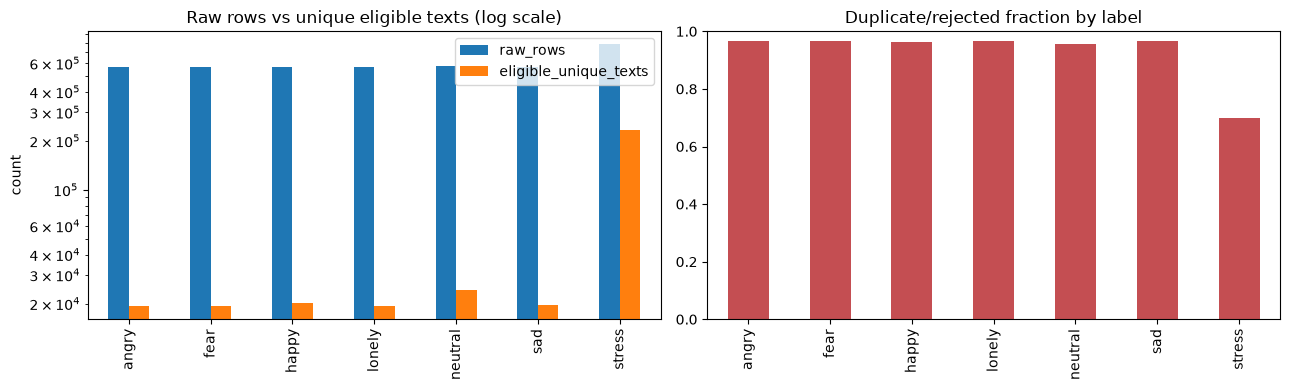

In [4]:
eligible_counts = {}
for i, label in id2label.items():
    eligible_counts[label] = db.execute(
        "SELECT COUNT(*) FROM texts WHERE label_mask = ?", (1 << i,)).fetchone()[0]

audit_table = pd.DataFrame({
    "raw_rows": pd.Series(audit["raw_label_counts"]),
    "eligible_unique_texts": pd.Series(eligible_counts)
}).reindex(LABELS)
audit_table["duplicate_or_rejected_fraction"] = 1 - (
    audit_table.eligible_unique_texts / audit_table.raw_rows)
display(audit_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
audit_table[["raw_rows", "eligible_unique_texts"]].plot.bar(ax=axes[0], logy=True)
axes[0].set_title("Raw rows vs unique eligible texts (log scale)")
axes[0].set_ylabel("count")
audit_table.duplicate_or_rejected_fraction.plot.bar(ax=axes[1], color="#c44e52")
axes[1].set_title("Duplicate/rejected fraction by label")
axes[1].set_ylim(0, 1)
plt.tight_layout()


## 3. Deterministic balanced sample of unique texts

The whole corpus is audited, then a deterministic hash-priority sample is taken independently within each label. Balancing makes macro comparisons stable but means accuracy estimates this balanced benchmark—not the dataset's original row-frequency distribution. The per-class cap is recorded rather than hidden.


In [5]:
def stable_priority(key, seed=SEED):
    payload = f"{seed}|{key}".encode("utf-8")
    return int.from_bytes(hashlib.blake2b(payload, digest_size=8).digest(), "big")

heaps = {label: [] for label in LABELS}
for key, text, mask, copies, source_id, source_file in db.execute(
        "SELECT key,text,label_mask,copies,first_id,first_file FROM texts "
        "WHERE (label_mask & (label_mask - 1)) = 0 ORDER BY key"):
    label = id2label[int(mask).bit_length() - 1]
    priority = stable_priority(key)
    item = (-priority, key, text, label, copies, source_id, source_file)
    heap = heaps[label]
    if len(heap) < MAX_UNIQUE_PER_CLASS:
        heapq.heappush(heap, item)
    elif priority < -heap[0][0]:
        heapq.heapreplace(heap, item)

records = []
for label, heap in heaps.items():
    for neg_priority, key, text, _, copies, source_id, source_file in heap:
        records.append({"text_key": key, "text": text, "label": label,
                        "original_copies": copies, "source_id": source_id,
                        "source_file": source_file, "sample_priority": -neg_priority})
sample = pd.DataFrame(records).sort_values(["label", "sample_priority"]).reset_index(drop=True)
assert sample.text_key.is_unique and set(sample.label) == set(LABELS)
display(sample.groupby("label").agg(n=("text", "size"),
    median_chars=("text", lambda s: int(s.str.len().median())),
    max_copies=("original_copies", "max")))
sample.to_parquet(OUT / "unique_balanced_sample.parquet", index=False)


,n,median_chars,max_copies
label,,,
angry,5000,310,20409
fear,5000,315,20408
happy,5000,299,20409
lonely,5000,318,20409
neutral,5000,284,3576
sad,5000,309,20408
stress,5000,369,2845


## 4. CLAWS tokenization and template-family discovery

CLAWS is used for the classical feature representation. It also helps infer structural template families **without using labels**:

- calculate document frequency for every token;
- keep corpus-common tokens as template scaffolding;
- replace consecutive uncommon tokens/numbers with a single `<SLOT>`;
- hash the resulting skeleton into `template_group`.

This is a reproducible heuristic, not a claim that templates are ground truth. The singleton rate and largest groups are printed so the split can be audited. If almost every group is a singleton, improve the grouping rule before trusting the test score.


In [6]:
from claws_tokenizer import segment

TOKEN_CACHE = OUT / f"claws_tokens_{MAX_UNIQUE_PER_CLASS}_per_class.parquet"
if TOKEN_CACHE.exists():
    tokenized = pd.read_parquet(TOKEN_CACHE)
    if set(tokenized.text_key) != set(sample.text_key):
        raise RuntimeError("Token cache does not match the current sample; delete it and rerun.")
    sample = sample.drop(columns=[c for c in ["tokens", "tokenized_text"] if c in sample]).merge(
        tokenized[["text_key", "tokens", "tokenized_text"]], on="text_key", how="left", validate="one_to_one")
else:
    started = time.perf_counter()
    sample["tokens"] = sample.text.map(lambda text: [t.strip() for t in segment(text) if t.strip()])
    if sample.tokens.map(len).eq(0).any():
        raise RuntimeError("CLAWS returned no tokens for at least one text.")
    sample["tokenized_text"] = sample.tokens.map(" ".join)
    sample[["text_key", "tokens", "tokenized_text"]].to_parquet(TOKEN_CACHE, index=False)
    print(f"Tokenized {len(sample):,} texts in {(time.perf_counter()-started)/60:.1f} minutes")

document_frequency = Counter()
for tokens in sample.tokens:
    document_frequency.update(set(tokens))
min_df = max(10, math.ceil(TEMPLATE_MIN_DF_RATE * len(sample)))
common_tokens = {token for token, count in document_frequency.items() if count >= min_df}

number_re = re.compile(r"^[0-9០-៩]+$")
def template_skeleton(tokens):
    skeleton = []
    for token in tokens:
        value = token if token in common_tokens and not number_re.match(token) else "<SLOT>"
        if value != "<SLOT>" or not skeleton or skeleton[-1] != "<SLOT>":
            skeleton.append(value)
    return " ".join(skeleton)

sample["template_skeleton"] = sample.tokens.map(template_skeleton)
sample["template_group"] = sample.template_skeleton.map(
    lambda s: hashlib.sha1(s.encode("utf-8")).hexdigest())
group_sizes = sample.groupby("template_group").size().sort_values(ascending=False)
print(f"Common scaffold tokens: {len(common_tokens):,} (minimum document frequency {min_df})")
print(f"Template groups: {len(group_sizes):,}; singleton texts: "
      f"{group_sizes.eq(1).sum()/len(sample):.1%}; largest group: {group_sizes.iloc[0]:,}")
display(sample.loc[sample.template_group.isin(group_sizes.head(5).index),
                   ["label", "template_skeleton", "text"]].head(20))


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


KeyboardInterrupt: 

## 5. Two split protocols

**Primary:** stratified grouped folds; no exact key or inferred template family can cross partitions.  
**Diagnostic:** ordinary stratified random split after exact deduplication; this deliberately shows how much template overlap can inflate the metric.

The same rows are used in both protocols. Model selection uses validation macro F1. Test labels remain untouched until the final evaluation cells.


In [ ]:
def assign_grouped_split(frame):
    result = pd.Series(index=frame.index, dtype="object")
    outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
    remaining_pos, test_pos = next(outer.split(frame, frame.label, frame.template_group))
    result.iloc[test_pos] = "test"
    remaining = frame.iloc[remaining_pos]
    inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED + 1)
    train_rel, val_rel = next(inner.split(remaining, remaining.label, remaining.template_group))
    result.loc[remaining.index[train_rel]] = "train"
    result.loc[remaining.index[val_rel]] = "validation"
    return result

def assign_random_split(frame):
    train_idx, holdout_idx = train_test_split(frame.index, test_size=2/7, stratify=frame.label,
                                               random_state=SEED)
    val_idx, test_idx = train_test_split(holdout_idx, test_size=0.5,
                                         stratify=frame.loc[holdout_idx, "label"], random_state=SEED + 1)
    result = pd.Series("train", index=frame.index, dtype="object")
    result.loc[val_idx] = "validation"
    result.loc[test_idx] = "test"
    return result

sample["split_grouped"] = assign_grouped_split(sample)
sample["split_random"] = assign_random_split(sample)
assert sample[["split_grouped", "split_random"]].notna().all().all()

for split_col in ["split_grouped", "split_random"]:
    print("\n", split_col)
    display(pd.crosstab(sample[split_col], sample.label).reindex(columns=LABELS))
    keys = {part: set(sample.loc[sample[split_col] == part, "text_key"])
            for part in ["train", "validation", "test"]}
    assert not (keys["train"] & keys["validation"] | keys["train"] & keys["test"] |
                keys["validation"] & keys["test"])

group_parts = sample.groupby("template_group").split_grouped.nunique()
assert group_parts.max() == 1, "A template group crossed the primary split."
random_group_parts = sample.groupby("template_group").split_random.nunique()
print(f"Random-split template groups crossing partitions: {(random_group_parts > 1).sum():,}")

split_columns = ["text_key", "text", "label", "template_group", "split_grouped", "split_random",
                 "source_id", "source_file", "original_copies"]
sample[split_columns].to_parquet(OUT / "experiment_splits.parquet", index=False)


## 6. Word TF–IDF + linear SVM

`TfidfVectorizer` receives space-joined CLAWS tokens and therefore learns **word unigrams and bigrams**, not character fragments. It is fit only on each protocol's training partition. `C` is selected only by validation macro F1. The test set is evaluated once after selection.


In [ ]:
def metric_row(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": p,
            "recall_macro": r, "f1_macro": f,
            "f1_weighted": f1_score(y_true, y_pred, labels=LABELS,
                                     average="weighted", zero_division=0)}

def run_word_baseline(frame, split_col):
    parts = {name: frame[frame[split_col] == name].copy()
             for name in ["train", "validation", "test"]}
    vectorizer = TfidfVectorizer(tokenizer=str.split, preprocessor=None, token_pattern=None,
                                 lowercase=False, ngram_range=(1, 2), min_df=2, max_df=0.98,
                                 max_features=200_000, sublinear_tf=True, dtype=np.float32)
    X_train = vectorizer.fit_transform(parts["train"].tokenized_text)
    X_val = vectorizer.transform(parts["validation"].tokenized_text)
    X_test = vectorizer.transform(parts["test"].tokenized_text)

    tuning = []
    for C in SVM_C_VALUES:
        candidate = LinearSVC(C=C).fit(X_train, parts["train"].label)
        tuning.append({"C": C, **metric_row(parts["validation"].label,
                                             candidate.predict(X_val))})
    tuning = pd.DataFrame(tuning).sort_values(["f1_macro", "C"], ascending=[False, True])
    best_c = float(tuning.iloc[0].C)
    model = LinearSVC(C=best_c).fit(X_train, parts["train"].label)
    test_pred = model.predict(X_test)

    dummy = DummyClassifier(strategy="most_frequent").fit(
        np.zeros((len(parts["train"]), 1)), parts["train"].label)
    dummy_pred = dummy.predict(np.zeros((len(parts["test"]), 1)))
    return {"parts": parts, "vectorizer": vectorizer, "model": model,
            "X_train": X_train, "X_test": X_test, "tuning": tuning,
            "pred": test_pred, "dummy_pred": dummy_pred}

runs = {}
for split_col in ["split_grouped", "split_random"]:
    print(f"Training {split_col} ...")
    runs[split_col] = run_word_baseline(sample, split_col)
    display(runs[split_col]["tuning"])

results = []
for split_col, run in runs.items():
    y = run["parts"]["test"].label
    results += [
        {"protocol": split_col, "model": "Majority", **metric_row(y, run["dummy_pred"])},
        {"protocol": split_col, "model": "CLAWS word TF-IDF + SVM", **metric_row(y, run["pred"])}]
results = pd.DataFrame(results)
display(results.sort_values(["protocol", "f1_macro"], ascending=[True, False]))

primary = runs["split_grouped"]
joblib.dump({"vectorizer": primary["vectorizer"], "model": primary["model"],
             "labels": LABELS, "cleaning": "NFC + controls-to-space + whitespace-collapse + trailing numeric-ID removal"},
            OUT / "claws_tfidf_svm.joblib")
results.to_csv(OUT / "classical_results.csv", index=False)


### Primary confusion matrix, per-class report and learned features

Top coefficients are an interpretability aid. They can reveal legitimate emotion vocabulary, generator artifacts, or suspicious shortcuts. They are not causal explanations.


In [ ]:
primary_test = primary["parts"]["test"].copy()
primary_test["word_svm_prediction"] = primary["pred"]
report = pd.DataFrame(classification_report(primary_test.label, primary["pred"], labels=LABELS,
                                             output_dict=True, zero_division=0)).T
display(report)

cm = confusion_matrix(primary_test.label, primary["pred"], labels=LABELS, normalize="true")
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Primary grouped test: row-normalized confusion matrix")
plt.xlabel("predicted"); plt.ylabel("true"); plt.tight_layout()

feature_names = np.asarray(primary["vectorizer"].get_feature_names_out())
top_features = {}
for class_index, label in enumerate(primary["model"].classes_):
    best = np.argsort(primary["model"].coef_[class_index])[-15:][::-1]
    top_features[label] = feature_names[best]
display(pd.DataFrame(top_features))
report.to_csv(OUT / "word_svm_classification_report.csv")


## 7. XLM-RoBERTa fine-tuning on the primary split

Set `RUN_XLMR=True` and rerun from configuration. This is supervised sequence classification with a learned seven-class head. It uses raw normalized Khmer text and XLM-R's native tokenizer. The validation set selects the best checkpoint by macro F1; the grouped test set is used only afterward.

Keep the saved split fixed if batch size or epochs change. Record hardware, runtime, package versions and any deviation from this configuration in the report.


In [ ]:
trainer = None
xlmr_prediction = None
if RUN_XLMR:
    import torch
    from datasets import Dataset, DatasetDict
    from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                              DataCollatorWithPadding, EarlyStoppingCallback, Trainer,
                              TrainingArguments, set_seed)
    set_seed(SEED)
    device_name = ("cuda" if torch.cuda.is_available() else
                   "mps" if torch.backends.mps.is_available() else "cpu")
    print("Transformer environment:", {"torch": torch.__version__,
          "transformers": metadata.version("transformers"), "device": device_name})

    grouped_parts = primary["parts"]
    datasets = DatasetDict({name: Dataset.from_pandas(
        part[["text", "label"]].assign(label=part.label.map(label2id)), preserve_index=False)
        for name, part in grouped_parts.items()})
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

    def encode(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)
    encoded = datasets.map(encode, batched=True, remove_columns=["text"])

    def transformer_metrics(prediction):
        pred = np.argmax(prediction.predictions, axis=-1)
        return metric_row([id2label[int(i)] for i in prediction.label_ids],
                          [id2label[int(i)] for i in pred])

    device_bs = XLMR_BATCH_SIZE
    args = TrainingArguments(
        output_dir=str(OUT / "xlmr_checkpoints"), learning_rate=2e-5,
        per_device_train_batch_size=device_bs, per_device_eval_batch_size=device_bs * 2,
        gradient_accumulation_steps=XLMR_GRAD_ACCUM, num_train_epochs=XLMR_EPOCHS,
        weight_decay=0.01, warmup_ratio=0.1, eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        save_total_limit=2, fp16=torch.cuda.is_available(), report_to="none", seed=SEED,
        data_seed=SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), label2id=label2id, id2label=id2label)
    trainer = Trainer(model=model, args=args, train_dataset=encoded["train"],
                      eval_dataset=encoded["validation"], tokenizer=tokenizer,
                      data_collator=DataCollatorWithPadding(tokenizer),
                      compute_metrics=transformer_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    started = time.perf_counter()
    trainer.train()
    xlmr_runtime_minutes = (time.perf_counter() - started) / 60
    output = trainer.predict(encoded["test"])
    xlmr_prediction = np.array([id2label[int(i)] for i in np.argmax(output.predictions, axis=-1)])
    trainer.save_model(OUT / "xlmr_best")
    tokenizer.save_pretrained(OUT / "xlmr_best")
    print(f"XLM-R training runtime: {xlmr_runtime_minutes:.1f} minutes")
else:
    print("XLM-R skipped. Set RUN_XLMR=True for the required final comparison; do not claim a result yet.")


## 8. Final comparison with uncertainty

The paired bootstrap resamples the same grouped test rows, preserving the direct comparison. It estimates test-sample uncertainty only—not variation from training seeds, tokenizer errors, model initialization or domain shift.


In [ ]:
final_predictions = {"Majority": primary["dummy_pred"],
                     "CLAWS word TF-IDF + SVM": primary["pred"]}
if xlmr_prediction is not None:
    final_predictions["XLM-R"] = xlmr_prediction

y_true = primary_test.label.to_numpy()
final_rows = [{"model": name, **metric_row(y_true, pred)}
              for name, pred in final_predictions.items()]
final_results = pd.DataFrame(final_rows).sort_values("f1_macro", ascending=False)
display(final_results)

def paired_bootstrap_f1(y, prediction_a, prediction_b=None, repeats=2_000, seed=SEED):
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(repeats):
        idx = rng.integers(0, len(y), len(y))
        score_a = f1_score(y[idx], prediction_a[idx], labels=LABELS,
                           average="macro", zero_division=0)
        if prediction_b is None:
            values.append(score_a)
        else:
            score_b = f1_score(y[idx], prediction_b[idx], labels=LABELS,
                               average="macro", zero_division=0)
            values.append(score_a - score_b)
    return np.percentile(values, [2.5, 50, 97.5])

svm_ci = paired_bootstrap_f1(y_true, np.asarray(primary["pred"]))
print("Word-SVM macro-F1 bootstrap [2.5%, median, 97.5%]:", np.round(svm_ci, 4))
if xlmr_prediction is not None:
    diff_ci = paired_bootstrap_f1(y_true, xlmr_prediction, np.asarray(primary["pred"]))
    print("XLM-R minus word-SVM macro-F1 [2.5%, median, 97.5%]:", np.round(diff_ci, 4))

prediction_table = primary_test[["text_key", "text", "label", "template_group"]].copy()
for name, pred in final_predictions.items():
    prediction_table[name] = pred
prediction_table.to_parquet(OUT / "grouped_test_predictions.parquet", index=False)
final_results.to_csv(OUT / "final_results.csv", index=False)


## 9. Residual leakage diagnostics and error analysis

Template groups are disjoint by construction, but the heuristic can miss paraphrases. The nearest-neighbor diagnostic uses the training-fitted **word** TF–IDF space. High similarity is a warning signal, not a reason to delete inconvenient test rows after seeing their labels.


In [ ]:
neighbors = NearestNeighbors(n_neighbors=1, metric="cosine", algorithm="brute", n_jobs=-1)
neighbors.fit(primary["X_train"])
distance, neighbor_index = neighbors.kneighbors(primary["X_test"])
similarity = 1 - distance[:, 0]
train_part = primary["parts"]["train"].reset_index(drop=True)
diagnostics = primary_test.reset_index(drop=True)[["text", "label", "word_svm_prediction"]].copy()
diagnostics["nearest_train_text"] = train_part.iloc[neighbor_index[:, 0]].text.to_numpy()
diagnostics["nearest_train_label"] = train_part.iloc[neighbor_index[:, 0]].label.to_numpy()
diagnostics["cosine_similarity"] = similarity
diagnostics["correct"] = diagnostics.label == diagnostics.word_svm_prediction
print("Grouped-test texts with nearest training cosine >= 0.90:", f"{np.mean(similarity >= .90):.1%}")
display(diagnostics.sort_values("cosine_similarity", ascending=False).head(20))
display(diagnostics[~diagnostics.correct].sort_values("cosine_similarity", ascending=False).head(30))
diagnostics.to_parquet(OUT / "leakage_and_error_diagnostics.parquet", index=False)


## 10. Inference

The classical artifact includes the CLAWS-trained vocabulary. XLM-R inference uses the saved Hugging Face model and tokenizer. SVM decision scores are margins, not calibrated probabilities.


In [ ]:
def predict_word_svm(text):
    if not isinstance(text, str):
        raise TypeError("text must be a string")
    normalized = clean_text(text)
    if not normalized or not khmer_re.search(normalized):
        raise ValueError("Enter non-empty text containing Khmer characters.")
    tokenized_text = " ".join(t.strip() for t in segment(normalized) if t.strip())
    return str(primary["model"].predict(primary["vectorizer"].transform([tokenized_text]))[0])

# Example (replace with genuinely new Khmer text):
# predict_word_svm("ខ្ញុំមានអារម្មណ៍សប្បាយរីករាយណាស់ថ្ងៃនេះ។")


## 11. Reporting checklist and defensible conclusions

Before submission:

- Execute all cells; set `RUN_XLMR=True` on suitable hardware.
- Report the raw row count, exact duplicate excess, conflicts, unique eligible texts, sampling cap and final split sizes.
- Make the **grouped** test result the headline. Label the random-split score as a leakage-sensitivity diagnostic, not a competing final result.
- Report macro precision, macro recall, macro F1, accuracy, per-class support, confusion matrix and bootstrap interval.
- Include CLAWS version, XLM-R checkpoint, hyperparameters, hardware, runtime and random seed.
- Discuss label ambiguity, synthetic/template language, tokenizer errors, class balancing and lack of an external human-reviewed test set.
- Never reuse the test set for changing preprocessing, template grouping, `C`, learning rate, epochs or checkpoint selection.

A valid conclusion should state what the executed evidence supports. If the random score is much higher than the grouped score, that is a central finding: the pilot's near-perfect accuracy was driven partly by structural overlap. If XLM-R does not beat the word model, report that honestly; a more complex model is not guaranteed to overcome dataset artifacts. The strongest next step is a separately sourced, manually validated test set from real Khmer text.
